# 07 - Matplotlib

**Sources:** Summer School *CursP_Numpy_Matplotlib* (Part II, "Matplotlib": simple plot, colours and line
widths, limits, ticks, tick labels, spines, legend, annotations, figures & subplots) plus the plots used
throughout *BonusSlides* and *CursP_sklearn*.

**Style note:** the slides use the `pylab` / `pl.plot(...)` *procedural* interface (MATLAB-like). It is fine for
quick looks, but modern code prefers the **object-oriented API**: `fig, ax = plt.subplots()` and then
`ax.plot(...)`. This notebook shows both and rebuilds the slides' progressive sin/cos figure.

Anatomy: a **Figure** (the canvas) contains one or more **Axes** (a plot area with x/y **Axis** objects,
ticks, labels, title) which contain **Artists** (lines, text, patches, images).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 90

## 1. The simplest plot

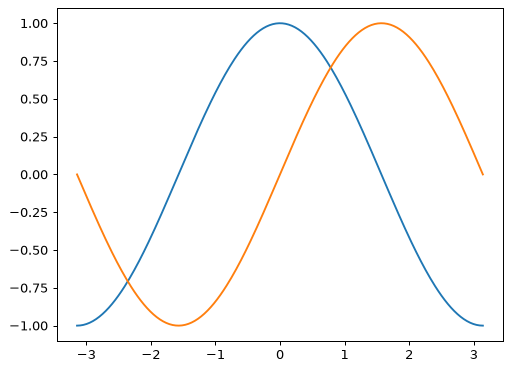

In [2]:
X = np.linspace(-np.pi, np.pi, 256, endpoint=True)
C, S = np.cos(X), np.sin(X)

# Procedural ("pylab") style, as in the slides
plt.plot(X, C)
plt.plot(X, S)
plt.show()

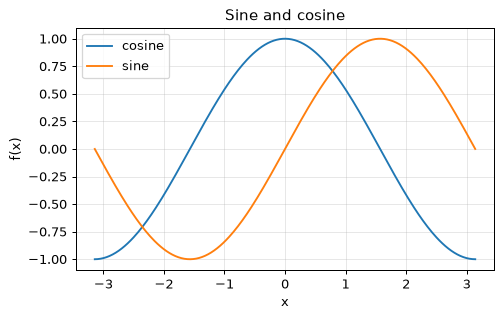

In [3]:
# Object-oriented style (recommended): explicit about which Axes we draw on
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(X, C, label="cosine")
ax.plot(X, S, label="sine")
ax.set(xlabel="x", ylabel="f(x)", title="Sine and cosine")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 2. Progressive refinement (the slides' example)
1. colours / line widths / figure size, 2. axis limits, 3. ticks, 4. tick labels with LaTeX,
5. move the spines, 6. legend, 7. annotations, 8. tick-label styling.

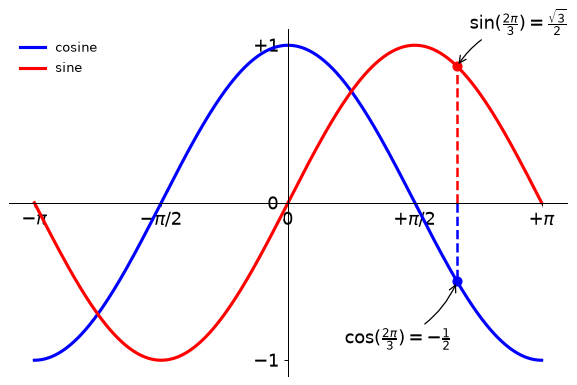

In [4]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=90)

# 1. colours, widths, styles
ax.plot(X, C, color="blue", linewidth=2.5, linestyle="-", label="cosine")
ax.plot(X, S, color="red", linewidth=2.5, linestyle="-", label="sine")

# 2. limits
ax.set_xlim(X.min() * 1.1, X.max() * 1.1)
ax.set_ylim(C.min() * 1.1, C.max() * 1.1)

# 3 + 4. ticks and tick labels (mathtext)
ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$+\pi/2$", r"$+\pi$"])
ax.set_yticks([-1, 0, +1])
ax.set_yticklabels([r"$-1$", r"$0$", r"$+1$"])

# 5. spines: remove top/right, centre the others on the origin
ax.spines["right"].set_color("none")
ax.spines["top"].set_color("none")
ax.xaxis.set_ticks_position("bottom")
ax.spines["bottom"].set_position(("data", 0))
ax.yaxis.set_ticks_position("left")
ax.spines["left"].set_position(("data", 0))

# 6. legend
ax.legend(loc="upper left", frameon=False)

# 7. annotate points
t = 2 * np.pi / 3
ax.plot([t, t], [0, np.cos(t)], color="blue", linewidth=2, linestyle="--")
ax.scatter([t], [np.cos(t)], 50, color="blue", zorder=3)
ax.annotate(r"$\cos(\frac{2\pi}{3})=-\frac{1}{2}$", xy=(t, np.cos(t)), xycoords="data",
            xytext=(-90, -50), textcoords="offset points", fontsize=14,
            arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=.2"))
ax.plot([t, t], [0, np.sin(t)], color="red", linewidth=2, linestyle="--")
ax.scatter([t], [np.sin(t)], 50, color="red", zorder=3)
ax.annotate(r"$\sin(\frac{2\pi}{3})=\frac{\sqrt{3}}{2}$", xy=(t, np.sin(t)), xycoords="data",
            xytext=(+10, +30), textcoords="offset points", fontsize=14,
            arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=.2"))

# 8. readable tick labels
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontsize(14)
    label.set_bbox(dict(facecolor="white", edgecolor="None", alpha=0.65))

plt.show()

## 3. Figures and subplots
`plt.subplots(nrows, ncols)` returns a figure and an array of axes. Use `sharex/sharey`, `constrained_layout`
or `tight_layout()` to avoid overlaps. For irregular layouts use `plt.subplot_mosaic`.

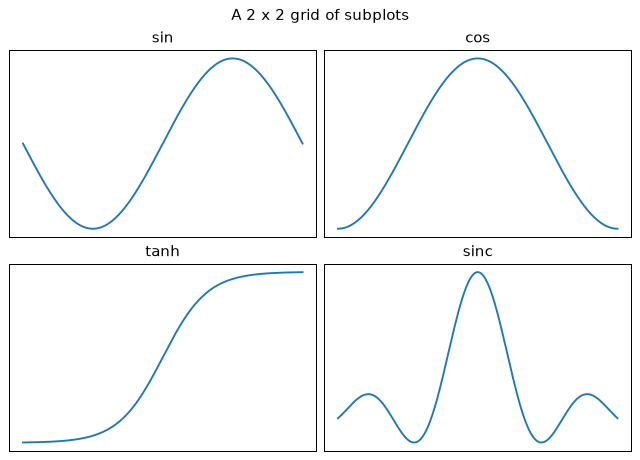

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(7, 5), constrained_layout=True)
for ax, (name, func) in zip(axes.ravel(), {"sin": np.sin, "cos": np.cos, "tanh": np.tanh, "sinc": np.sinc}.items()):
    ax.plot(X, func(X))
    ax.set_title(name)
    ax.set_xticks(())
    ax.set_yticks(())
fig.suptitle("A 2 x 2 grid of subplots")
plt.show()

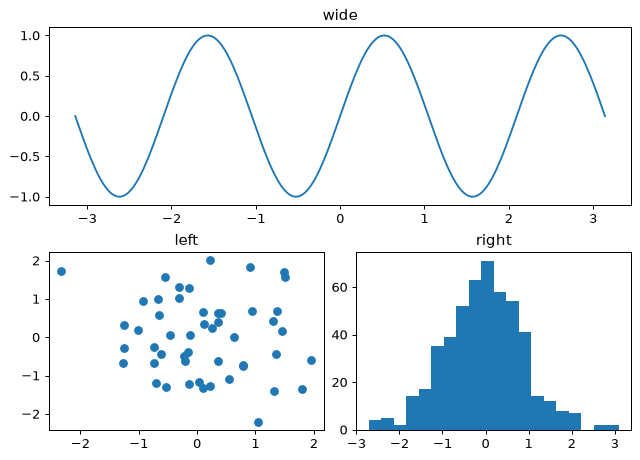

In [6]:
fig, axd = plt.subplot_mosaic([["wide", "wide"], ["left", "right"]], figsize=(7, 5), constrained_layout=True)
axd["wide"].plot(X, np.sin(3 * X)); axd["wide"].set_title("wide")
axd["left"].scatter(*np.random.default_rng(0).normal(size=(2, 50))); axd["left"].set_title("left")
axd["right"].hist(np.random.default_rng(1).normal(size=500), bins=20); axd["right"].set_title("right")
plt.show()

## 4. Plot types you will use constantly

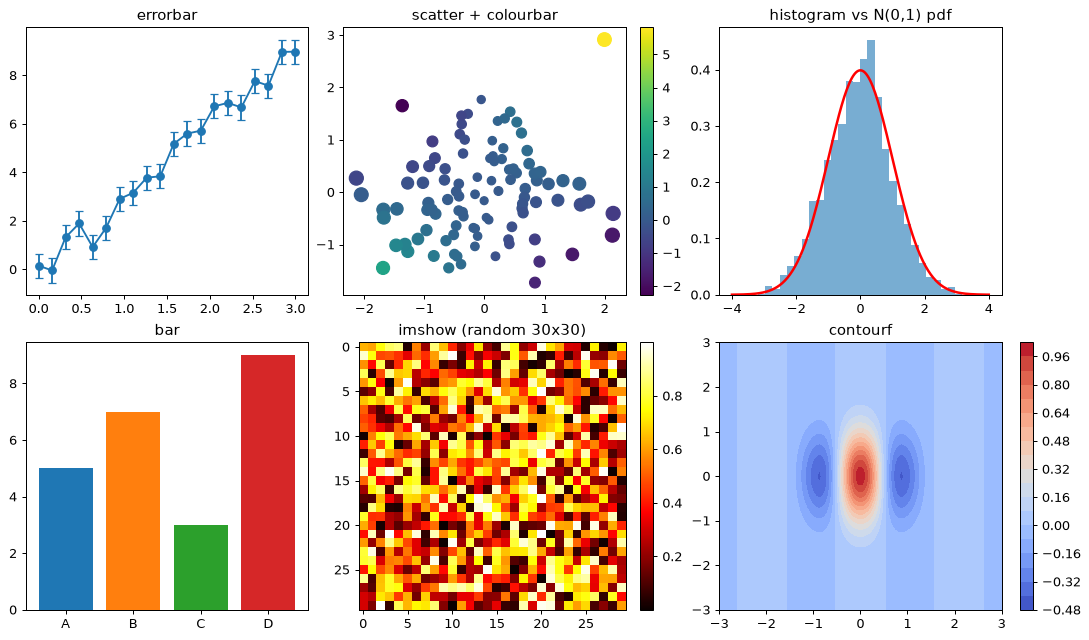

In [7]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)

# line + markers + error bars
x = np.linspace(0, 3, 20)
axes[0, 0].errorbar(x, 3 * x + rng.normal(0, 0.5, 20), yerr=0.5, fmt="o-", capsize=3)
axes[0, 0].set_title("errorbar")

# scatter with colour + size mapped to data
pts = rng.normal(size=(100, 2))
sc = axes[0, 1].scatter(pts[:, 0], pts[:, 1], c=pts[:, 0] * pts[:, 1], s=40 + 40 * np.abs(pts[:, 0]), cmap="viridis")
fig.colorbar(sc, ax=axes[0, 1])
axes[0, 1].set_title("scatter + colourbar")

# histogram + theoretical density (density estimation slide)
data = rng.normal(size=2000)
axes[0, 2].hist(data, bins=30, density=True, alpha=0.6)
grid = np.linspace(-4, 4, 200)
axes[0, 2].plot(grid, np.exp(-grid ** 2 / 2) / np.sqrt(2 * np.pi), "r-", lw=2)
axes[0, 2].set_title("histogram vs N(0,1) pdf")

# bar chart
cats = ["A", "B", "C", "D"]
axes[1, 0].bar(cats, [5, 7, 3, 9], color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
axes[1, 0].set_title("bar")

# images / heat-maps (2D arrays)
image = rng.random((30, 30))
im = axes[1, 1].imshow(image, cmap="hot")
fig.colorbar(im, ax=axes[1, 1])
axes[1, 1].set_title("imshow (random 30x30)")

# contour plot of a 2-D function
xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
zz = np.exp(-(xx ** 2 + yy ** 2)) * np.cos(3 * xx)
cs = axes[1, 2].contourf(xx, yy, zz, levels=20, cmap="coolwarm")
fig.colorbar(cs, ax=axes[1, 2])
axes[1, 2].set_title("contourf")
plt.show()

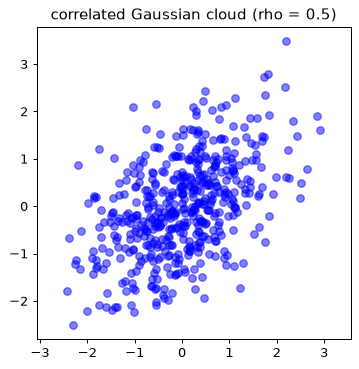

In [8]:
# Multivariate normal from the bonus slides
mean = [0, 0]
cov = [[1, 0.5], [0.5, 1]]
x, y = np.random.default_rng(5).multivariate_normal(mean, cov, 500).T
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(x, y, "bo", alpha=0.5)
ax.axis("equal")
ax.set_title("correlated Gaussian cloud (rho = 0.5)")
plt.show()

## 5. 3-D plots
Built in via `projection="3d"` (the slides used the separate `mayavi` package).

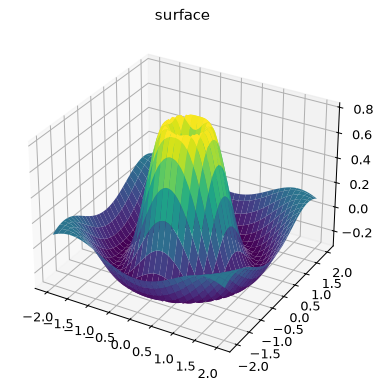

In [9]:
xx, yy = np.meshgrid(np.linspace(-2, 2, 60), np.linspace(-2, 2, 60))
zz = np.sin(np.sqrt(xx ** 2 + yy ** 2) * 3) / (1 + xx ** 2 + yy ** 2)
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(xx, yy, zz, cmap="viridis", linewidth=0)
ax.set_title("surface")
plt.show()

## 6. Figure parameters and saving
`plt.figure(num, figsize=(w, h) in inches, dpi, facecolor, edgecolor, frameon)`. Save with
`fig.savefig("name.png", dpi=150, bbox_inches="tight")`; `.pdf` / `.svg` give vector graphics.

In [10]:
import tempfile, os
fig, ax = plt.subplots(figsize=(3, 2))
ax.plot([0, 1], [0, 1])
path = os.path.join(tempfile.gettempdir(), "demo_plot.png")
fig.savefig(path, dpi=120, bbox_inches="tight")
print(os.path.getsize(path) > 0, plt.style.available[:5])
plt.close(fig)                           # free memory when creating many figures
os.remove(path)

True ['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast']


### Styles and colour maps
`plt.style.use("seaborn-v0_8-whitegrid")` / `"ggplot"` / `"bmh"` change the whole look;
colour maps: sequential (`viridis`), diverging (`coolwarm`), qualitative (`tab10`). Avoid `jet`.

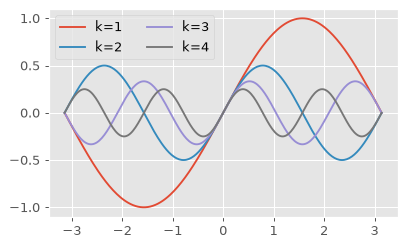

In [11]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(5, 3))
    for k in range(1, 5):
        ax.plot(X, np.sin(k * X) / k, label=f"k={k}")
    ax.legend(ncol=2)
    plt.show()

## 7. Animation-free "interactivity"
In Jupyter, `%matplotlib widget` (needs `ipympl`) gives pan/zoom; `%matplotlib inline` gives static images.
In scripts remember `plt.show()` at the end.

## Exercises

**A.** Re-draw the progressive sin/cos figure as a *function* `make_trig_figure(ax)` that takes an Axes, then use
it in a 1 x 2 subplot with different frequency parameters.

**B.** Plot the Taylor approximations of `sin(x)` of order 1, 3, 5, 7 against the exact curve, limiting `y` to
`[-2, 2]`. Annotate where each approximation leaves the 1% error band.

**C.** Generate two clusters with `make_blobs`-style code, scatter-plot them coloured by label and draw each
cluster mean with a big `X` marker and a legend.

**D.** Re-create the iris scatter matrix (4 x 4 grid of axes, histograms on the diagonal) using only Matplotlib
(you will meet `pandas.plotting.scatter_matrix` in notebook 08).

In [12]:
# Your turn